# Tarea 27: K-Means 

In [2]:
# load libraries 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans

In [3]:
# load iris data set 
df = pd.read_csv('iris.csv')
df.sample(5)

,sepal.length,sepal.width,petal.length,petal.width,variety
35,5.0,3.2,1.2,0.2,Setosa
110,6.5,3.2,5.1,2.0,Virginica
0,5.1,3.5,1.4,0.2,Setosa
5,5.4,3.9,1.7,0.4,Setosa
131,7.9,3.8,6.4,2.0,Virginica


In [15]:
df.variety.unique()

<StringArray>
['Setosa', 'Versicolor', 'Virginica']
Length: 3, dtype: str

Selección de las columnas de 'petal.length' y 'petal.width' para hacer el primer cluster

In [5]:
fields = df.iloc[:,[2, 3]].values
fields

array([[1.4, 0.2],
       [1.4, 0.2],
       [1.3, 0.2],
       [1.5, 0.2],
       [1.4, 0.2],
       [1.7, 0.4],
       [1.4, 0.3],
       [1.5, 0.2],
       [1.4, 0.2],
       [1.5, 0.1],
       [1.5, 0.2],
       [1.6, 0.2],
       [1.4, 0.1],
       [1.1, 0.1],
       [1.2, 0.2],
       [1.5, 0.4],
       [1.3, 0.4],
       [1.4, 0.3],
       [1.7, 0.3],
       [1.5, 0.3],
       [1.7, 0.2],
       [1.5, 0.4],
       [1. , 0.2],
       [1.7, 0.5],
       [1.9, 0.2],
       [1.6, 0.2],
       [1.6, 0.4],
       [1.5, 0.2],
       [1.4, 0.2],
       [1.6, 0.2],
       [1.6, 0.2],
       [1.5, 0.4],
       [1.5, 0.1],
       [1.4, 0.2],
       [1.5, 0.2],
       [1.2, 0.2],
       [1.3, 0.2],
       [1.4, 0.1],
       [1.3, 0.2],
       [1.5, 0.2],
       [1.3, 0.3],
       [1.3, 0.3],
       [1.3, 0.2],
       [1.6, 0.6],
       [1.9, 0.4],
       [1.4, 0.3],
       [1.6, 0.2],
       [1.4, 0.2],
       [1.5, 0.2],
       [1.4, 0.2],
       [4.7, 1.4],
       [4.5, 1.5],
       [4.9,

Búsqueda del numero de cluster optimo para este arreglo

In [8]:
wcss = []
for index in range(1, 11):
    kmeans = KMeans(n_clusters=index, init='k-means++', random_state=2)
    kmeans.fit(fields)

    wcss.append(kmeans.inertia_)
    print(f'Number of clusters: {index}, inertia: {kmeans.inertia_} ')

Number of clusters: 1, inertia: 550.8953333333333 
Number of clusters: 2, inertia: 86.39021984551395 
Number of clusters: 3, inertia: 31.412885668276978 
Number of clusters: 4, inertia: 19.483000899685116 
Number of clusters: 5, inertia: 13.916908757908757 
Number of clusters: 6, inertia: 11.070652341896277 
Number of clusters: 7, inertia: 9.500978672428491 
Number of clusters: 8, inertia: 8.06218530020704 
Number of clusters: 9, inertia: 7.594788048552754 
Number of clusters: 10, inertia: 6.07486965811966 


Text(0, 0.5, 'WCSS')

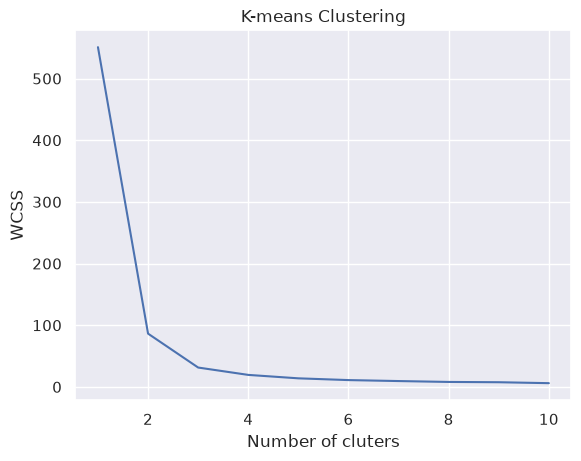

In [7]:
# Elbow method 
sns.set_theme()
plt.plot(range(1, 11), wcss)
plt.title('K-means Clustering')
plt.xlabel('Number of cluters')
plt.ylabel('WCSS')

De manera intuitiva se selecciona el numero optimo de cluster $k=3$, pero mas adelante se validara con el metodo de silueta. 

In [9]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=2)
cluster_values = kmeans.fit_predict(fields)
cluster_values

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0, 0, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], dtype=int32)

Enseguida se grafican los resultados para visualizar

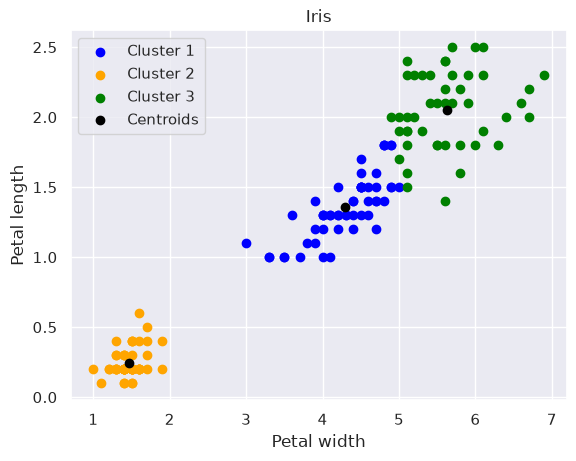

In [10]:
# Plot the cluster 
plt.scatter(fields[cluster_values==0, 0], fields[cluster_values==0, 1], c = 'blue', label = 'Cluster 1')
plt.scatter(fields[cluster_values==1, 0], fields[cluster_values==1, 1], c = 'orange', label = 'Cluster 2')
plt.scatter(fields[cluster_values==2, 0], fields[cluster_values==2, 1], c = 'green', label = 'Cluster 3')

plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c = 'black', label = 'Centroids')

plt.title('Iris')
plt.xlabel('Petal width')
plt.ylabel('Petal length')
plt.legend()

De este primer ejercicio se logra ver que los cluster están bien definidos y no tiene traslapes. Para comprobar si 3 es un numero optimo se hara uso del metodo de la silueta.

In [12]:
# load silhouette library
from sklearn.metrics import silhouette_score

In [13]:
X = df.iloc[:, [2,3]].to_numpy()

for j in range(2, 12):
    kmeans = KMeans(n_clusters = j, random_state=2)
    kmeans.fit_predict(X)

    # calculate silhouette score
    score = silhouette_score(X, kmeans.labels_, metric= 'euclidean')
    print(f'Score silhouette, k = {j},  score: {score:.2f} ')

Score silhouette, k = 2,  score: 0.77 
Score silhouette, k = 3,  score: 0.66 
Score silhouette, k = 4,  score: 0.61 
Score silhouette, k = 5,  score: 0.59 
Score silhouette, k = 6,  score: 0.58 
Score silhouette, k = 7,  score: 0.59 
Score silhouette, k = 8,  score: 0.56 
Score silhouette, k = 9,  score: 0.54 
Score silhouette, k = 10,  score: 0.57 
Score silhouette, k = 11,  score: 0.55 


De acuerdo a los datos, el numero optimo de cluster es $k=2$. Se repetirá el ejercicio anterior.

In [16]:
kmeans = KMeans(n_clusters=2, init='k-means++', random_state=2)
cluster_values = kmeans.fit_predict(fields)

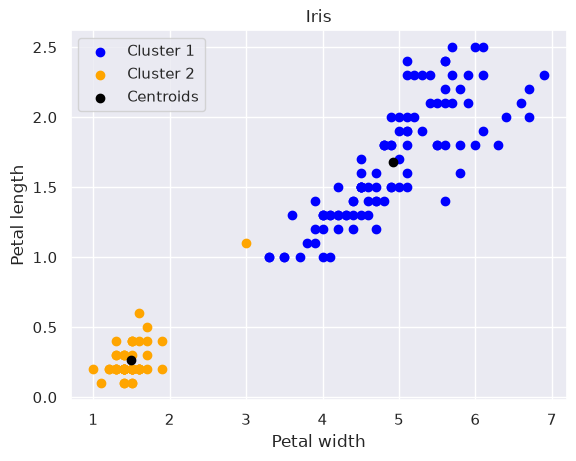

In [17]:
# Plot the cluster 
plt.scatter(fields[cluster_values==0, 0], fields[cluster_values==0, 1], c = 'blue', label = 'Cluster 1')
plt.scatter(fields[cluster_values==1, 0], fields[cluster_values==1, 1], c = 'orange', label = 'Cluster 2')

plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c = 'black', label = 'Centroids')

plt.title('Iris')
plt.xlabel('Petal width')
plt.ylabel('Petal length')
plt.legend()

Con $k=2$ la gráfica muestra ahora los clusters mas definidos con la excepción del punto naranja que se encuentra cerca de los puntos azules. La gráfica muestra un grupos con mas separación.

# Reduccion de dimensionalidad PCA

Para considerar todas las características del conjunto de datos se usara la reducción de dimensionalidad a dos variables, para verificar cual es el numero de cluster optimo en este caso.

In [18]:
fields2 = df.iloc[:, [0,1,2,3]].values
fields2

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [19]:
# load decomposition pca library

from sklearn import decomposition

pca = decomposition.PCA(n_components=2) 
pca.fit(fields2)
fields2 = pca.transform(fields2)
fields2

array([[-2.68412563,  0.31939725],
       [-2.71414169, -0.17700123],
       [-2.88899057, -0.14494943],
       [-2.74534286, -0.31829898],
       [-2.72871654,  0.32675451],
       [-2.28085963,  0.74133045],
       [-2.82053775, -0.08946138],
       [-2.62614497,  0.16338496],
       [-2.88638273, -0.57831175],
       [-2.6727558 , -0.11377425],
       [-2.50694709,  0.6450689 ],
       [-2.61275523,  0.01472994],
       [-2.78610927, -0.235112  ],
       [-3.22380374, -0.51139459],
       [-2.64475039,  1.17876464],
       [-2.38603903,  1.33806233],
       [-2.62352788,  0.81067951],
       [-2.64829671,  0.31184914],
       [-2.19982032,  0.87283904],
       [-2.5879864 ,  0.51356031],
       [-2.31025622,  0.39134594],
       [-2.54370523,  0.43299606],
       [-3.21593942,  0.13346807],
       [-2.30273318,  0.09870885],
       [-2.35575405, -0.03728186],
       [-2.50666891, -0.14601688],
       [-2.46882007,  0.13095149],
       [-2.56231991,  0.36771886],
       [-2.63953472,

In [22]:
# try several values of number of clusters to find the more optimal
wcss2 = []
for index in range(1, 11):
    kmeans = KMeans(n_clusters=index, init='k-means++', random_state=2)
    kmeans.fit(fields2)

    wcss2.append(kmeans.inertia_)
    print(f'Number of clusters: {index}, inertia: {kmeans.inertia_} ')

Number of clusters: 1, inertia: 666.1659556405607 
Number of clusters: 2, inertia: 137.155301128184 
Number of clusters: 3, inertia: 63.81994202200115 
Number of clusters: 4, inertia: 42.38609427321202 
Number of clusters: 5, inertia: 35.600967387792565 
Number of clusters: 6, inertia: 28.248464076196676 
Number of clusters: 7, inertia: 24.715932758691338 
Number of clusters: 8, inertia: 20.047235886335603 
Number of clusters: 9, inertia: 16.057834999187616 
Number of clusters: 10, inertia: 14.421718896211257 


Text(0, 0.5, 'WCSS')

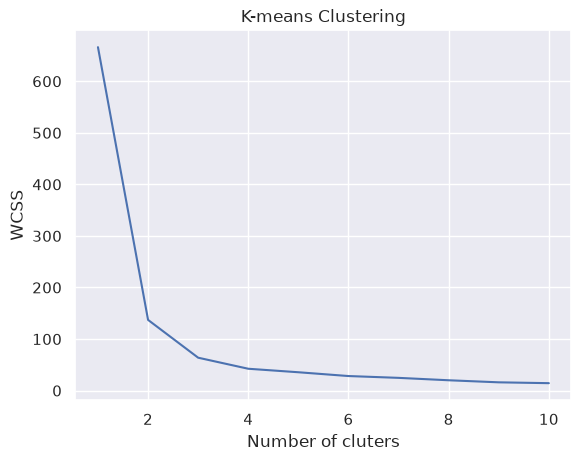

In [23]:
# Elbow method 
sns.set_theme()
plt.plot(range(1, 11), wcss2)
plt.title('K-means Clustering')
plt.xlabel('Number of cluters')
plt.ylabel('WCSS')

In [24]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=2)
cluster_values = kmeans.fit_predict(fields2)
cluster_values

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 0, 2, 2, 2, 2,
       2, 0, 2, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0], dtype=int32)

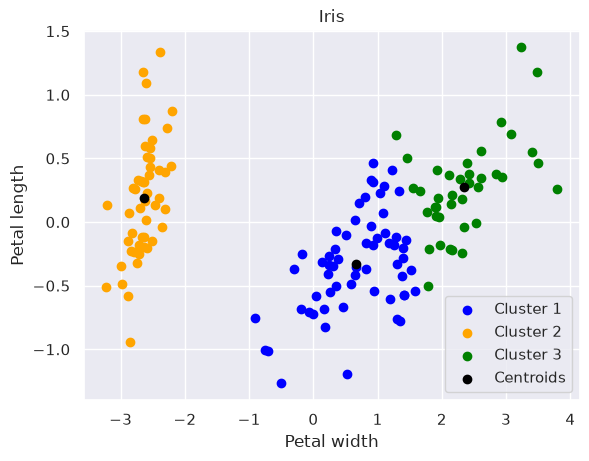

In [ ]:
# Plot the cluster 
plt.scatter(fields2[cluster_values==0, 0], fields2[cluster_values==0, 1], c = 'blue', label = 'Cluster 1')
plt.scatter(fields2[cluster_values==1, 0], fields2[cluster_values==1, 1], c = 'orange', label = 'Cluster 2')
plt.scatter(fields2[cluster_values==2, 0], fields2[cluster_values==2, 1], c = 'green', label = 'Cluster 3')

plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c = 'black', label = 'Centroids')

plt.title('Iris')
plt.xlabel('PDA1')
plt.ylabel('PDA2')
plt.legend()

Al igual que ene l caso anterior se observa que el cluster 1 y 3 estan bien definido pero estan muy cercas el uno del otro.

Metodo de la silueta para ver el score.

In [27]:
X =  fields2

for j in range(2, 12):
    kmeans = KMeans(n_clusters = j, random_state=2)
    kmeans.fit_predict(X)

    # calculate silhouette score
    score = silhouette_score(X, kmeans.labels_, metric= 'euclidean')
    print(f'Score silhouette, k = {j},  score: {score:.2f} ')

Score silhouette, k = 2,  score: 0.71 
Score silhouette, k = 3,  score: 0.60 
Score silhouette, k = 4,  score: 0.56 
Score silhouette, k = 5,  score: 0.51 
Score silhouette, k = 6,  score: 0.40 
Score silhouette, k = 7,  score: 0.41 
Score silhouette, k = 8,  score: 0.42 
Score silhouette, k = 9,  score: 0.41 
Score silhouette, k = 10,  score: 0.39 
Score silhouette, k = 11,  score: 0.39 


# Conclusiones 

En este ejercicio, se puede concluir que aun que el número de clusters ideal debería ser 3, que es el equivalente a los 3 tipos de flores. El resultado del análisis numérico muestra los cluster 1 y 3 son muy similares por los que el método de la silueta arroja como resultado mas optimo el número 2, que los que se ve en las gráficas.

Lo que se podría hacer para mejorar el proceso es considerar las tipos de flores, convirtiendo en variables numéricas y volver a hacer el proceso.  